In [1]:
from sklearn import datasets
digits = datasets.load_digits()
X,y = digits.data,digits.target

In [4]:
X,y = digits.data,digits.target

In [22]:
X = torch.randn(100, 64).double()

In [23]:
type(X)

torch.Tensor

In [1]:
#例子 1：基础用法

import torch
import torch.nn as nn

# 定义一个线性层：输入维度为 5，输出维度为 3
linear_layer = nn.Linear(in_features=5, out_features=3)

# 创建一个输入张量：批量大小为 2，每个样本有 5 个特征
input = torch.randn(2, 5)
print("Input shape:", input.shape)  # torch.Size([2, 5])

# 将输入传递给线性层
output = linear_layer(input)
print("Output shape:", output.shape) # torch.Size([2, 3])

# 查看层的内部参数
print("Weight shape:", linear_layer.weight.shape) # torch.Size([3, 5])
print("Bias shape:", linear_layer.bias.shape)     # torch.Size([3])



Input shape: torch.Size([2, 5])
Output shape: torch.Size([2, 3])
Weight shape: torch.Size([3, 5])
Bias shape: torch.Size([3])


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn import datasets

# 假设我们有一些训练数据（这里用随机数据演示）
# 在实际应用中，你会使用真实的数据集如 MNIST, CIFAR-10 等

# 1. 准备数据
def prepare_data(choice=1):
    # 生成模拟数据：1000个样本，每个样本784维（类似28x28图像展开）
    num_samples = 1000
    input_size = 64 # 784
    num_classes = 10
    
    # 随机生成输入数据和标签
    # X = torch.randn(num_samples, input_size).double()
    # y = torch.randint(0, num_classes, (num_samples,)).double()
    digits = datasets.load_digits()
    if choice == 1 :
        X,y = torch.tensor(digits.data[0:num_samples,:]),torch.tensor(digits.target[0:num_samples])
    elif choice == 2 :
        X,y = torch.tensor(digits.data[num_samples:,:]),torch.tensor(digits.target[num_samples:])
    elif choice == 3 :
        rowsidx = np.random.choice(arr.shape[0], size=200, replace=True)
        X,y = torch.tensor(digits.data[rowsidx,:]),torch.tensor(digits.target[rowsidx])
    
    # 创建数据集和数据加载器
    dataset = TensorDataset(X, y)
    train_loader = DataLoader(dataset, batch_size=32, shuffle=True)
    
    return train_loader

# 2. 定义模型（使用之前定义的神经网络）
class SimpleNeuralNetwork(nn.Module):
    def __init__(self):
        super(SimpleNeuralNetwork, self).__init__()
        # self.layer1 = nn.Linear(784, 128).double()
        self.layer1 = nn.Linear(64, 128).double()
        self.layer2 = nn.Linear(128, 64).double()
        self.output_layer = nn.Linear(64, 10).double()
        self.dropout = nn.Dropout(0.2)  # 添加dropout防止过拟合

    def forward(self, x):
        x = torch.relu(self.layer1(x))
        x = self.dropout(x)  # 在激活后添加dropout
        x = torch.relu(self.layer2(x))
        x = self.dropout(x)
        x = self.output_layer(x)
        return x

# 3. 训练函数
def train_model(m=None):
    # 准备数据
    train_loader = prepare_data()
    
    # 初始化模型
    if m is None:
        model = SimpleNeuralNetwork()
    else:
        model = m
    
    # 定义损失函数和优化器
    criterion = nn.CrossEntropyLoss()  # 交叉熵损失，适用于多分类
    optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam优化器
    
    # 学习率调度器（可选）
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
    
    # 记录训练过程中的损失和准确率
    train_losses = []
    train_accuracies = []
    
    # 训练循环
    num_epochs = 20
    
    for epoch in range(num_epochs):
        model.train()  # 设置模型为训练模式（启用dropout等）
        running_loss = 0.0
        correct = 0
        total = 0
        
        for batch_idx, (data, targets) in enumerate(train_loader):
            # 1. 梯度清零
            optimizer.zero_grad()
            
            # 2. 前向传播
            outputs = model(data)
            
            # 3. 计算损失
            loss = criterion(outputs, targets)
            
            # 4. 反向传播
            loss.backward()
            
            # 5. 参数更新
            optimizer.step()
            
            # 统计信息
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
        
        # 更新学习率
        scheduler.step()
        
        # 计算每个epoch的平均损失和准确率
        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total
        
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)
        
        print(f'Epoch [{epoch+1}/{num_epochs}], '
              f'Loss: {epoch_loss:.4f}, '
              f'Accuracy: {epoch_accuracy:.2f}%')
    
    return model, train_losses, train_accuracies

# 4. 可视化训练过程
def plot_training_curves(losses, accuracies):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    # 绘制损失曲线
    ax1.plot(losses)
    ax1.set_title('Training Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.grid(True)
    
    # 绘制准确率曲线
    ax2.plot(accuracies)
    ax2.set_title('Training Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

# 5. 模型评估
def evaluate_model(model, test_loader):
    model.eval()  # 设置模型为评估模式（禁用dropout等）
    correct = 0
    total = 0
    if test_loader is None:
        test_loader = prepare_data(choice=2)
    with torch.no_grad():  # 在评估时不需要计算梯度
        for data, targets in test_loader:
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    
    accuracy = 100 * correct / total
    print(f'Test Accuracy: {accuracy:.2f}%')
    return accuracy

# 6. 保存和加载模型
def save_model(model, path='model.pth'):
    torch.save(model.state_dict(), path)
    print(f'Model saved to {path}')

def load_model(model, path='model.pth'):
    model.load_state_dict(torch.load(path))
    model.eval()
    print(f'Model loaded from {path}')
    return model

# 主函数
if __name__ == "__main__":
    # 训练模型
    print("开始训练模型...")
    model = SimpleNeuralNetwork()
    trained_model, losses, accuracies = train_model(m=model)
    
    # 可视化训练过程
    plot_training_curves(losses, accuracies)
    
    # 保存模型
    save_model(trained_model)
    
    print("训练完成！")

In [2]:
test_loader = prepare_data(choice=2)


def evaluate_model(model, test_loader):
    model.eval()  # 设置模型为评估模式（禁用dropout等）
    correct = 0
    total = 0
    if test_loader is None:
        test_loader = prepare_data(choice=2)
    with torch.no_grad():  # 在评估时不需要计算梯度
        for data, targets in test_loader:
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    
    accuracy = 100 * correct / total
    print(f'Test Accuracy: {accuracy:.2f}%')
    return accuracy

#下面是对指定数据的预测。
x,y = next(iter(test_loader))
y2 = model(x)
y3 = trained_model(x)

[[tensor([[ 0.,  0.,  0.,  ...,  0.,  0.,  0.],
          [ 0.,  4., 15.,  ..., 12.,  3.,  0.],
          [ 0.,  0.,  8.,  ...,  2.,  0.,  0.],
          ...,
          [ 0.,  0.,  0.,  ...,  0.,  0.,  0.],
          [ 0.,  0.,  1.,  ...,  0.,  0.,  0.],
          [ 0.,  2., 16.,  ...,  5.,  0.,  0.]], dtype=torch.float64),
  tensor([1, 2, 2, 9, 4, 2, 3, 7, 8, 8, 9, 5, 3, 2, 1, 5, 7, 3, 2, 3, 0, 7, 2, 3,
          0, 6, 8, 2, 5, 1, 7, 5])],
 [tensor([[ 0.,  3., 12.,  ..., 16., 16.,  3.],
          [ 0.,  0.,  7.,  ...,  0.,  0.,  0.],
          [ 0.,  0.,  7.,  ...,  0.,  0.,  0.],
          ...,
          [ 0.,  0.,  0.,  ...,  0.,  0.,  0.],
          [ 0.,  0.,  5.,  ...,  7.,  0.,  0.],
          [ 0.,  0.,  6.,  ...,  4.,  0.,  0.]], dtype=torch.float64),
  tensor([2, 5, 8, 0, 6, 0, 8, 4, 2, 9, 1, 2, 8, 8, 5, 8, 8, 7, 1, 9, 6, 0, 3, 3,
          8, 2, 0, 8, 1, 9, 1, 9])],
 [tensor([[0., 0., 6.,  ..., 0., 0., 0.],
          [0., 0., 4.,  ..., 7., 0., 0.],
          [0., 1., 8.,  ..

In [3]:
evaluate_model(model,test_loader)


Test Accuracy: 94.35%


94.35382685069008

In [16]:
y

tensor([1, 0, 1, 1, 2, 0, 8, 9, 1, 1, 7, 9, 2, 9, 4, 5, 7, 1, 5, 9, 2, 2, 1, 5,
        9, 0, 6, 8, 5, 0, 3, 0])

In [14]:
torch.argmax(y2,axis=1)

tensor([9, 6, 1, 1, 2, 0, 8, 9, 9, 1, 7, 9, 2, 9, 4, 5, 7, 1, 5, 9, 2, 2, 1, 5,
        9, 0, 6, 8, 5, 0, 3, 0])

In [15]:
torch.argmax(y3,axis=1)

tensor([9, 6, 1, 1, 2, 0, 8, 9, 9, 1, 7, 9, 2, 9, 4, 5, 7, 1, 5, 9, 2, 2, 1, 5,
        9, 0, 6, 8, 5, 0, 3, 0])

In [17]:
model.parameters

<bound method Module.parameters of SimpleNeuralNetwork(
  (layer1): Linear(in_features=64, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=64, bias=True)
  (output_layer): Linear(in_features=64, out_features=10, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)>

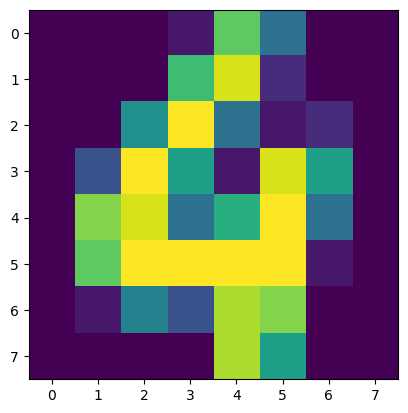

In [20]:
plt.imshow(a[0,:].reshape(8,8) )

In [ ]:
# 定义一个没有偏置的线性层
linear_layer_no_bias = nn.Linear(5, 3, bias=False)
print("Bias is None:", linear_layer_no_bias.bias is None) # 输出：True

In [3]:
#例子 3：更高维度的输入
# 输入形状为 (3, 4, 5)，例如：3个样本，每个样本是4x5的矩阵
input_3d = torch.randn(3, 4, 5)
linear_layer = nn.Linear(5, 10) # 只改变最后一个维度（5 -> 10）

output_3d = linear_layer(input_3d)
print("Input shape:", input_3d.shape)   # torch.Size([3, 4, 5])
print("Output shape:", output_3d.shape) # torch.Size([3, 4, 10])

Input shape: torch.Size([3, 4, 5])
Output shape: torch.Size([3, 4, 10])


In [4]:
#在神经网络中的典型用法
class SimpleNeuralNetwork(nn.Module):
    def __init__(self):
        super(SimpleNeuralNetwork, self).__init__()
        self.layer1 = nn.Linear(784, 128) # 从784维（如图像像素）映射到128维
        self.layer2 = nn.Linear(128, 64)  # 从128维映射到64维
        self.output_layer = nn.Linear(64, 10) # 从64维映射到10维（如10个分类）

    def forward(self, x):
        x = torch.relu(self.layer1(x)) # 线性变换后接ReLU激活函数
        x = torch.relu(self.layer2(x))
        x = self.output_layer(x)
        return x

# 使用模型
model = SimpleNeuralNetwork()
input_data = torch.randn(32, 784) # 批量大小32，特征784
predictions = model(input_data)
print(predictions.shape) # torch.Size([32, 10])

torch.Size([32, 10])


In [14]:
X = torch.randn(5, 8)
# plt.hist(X.flatten())

y = torch.randint(0, 10, (5,))
dataset = TensorDataset(X, y)

In [19]:
dataset.tensors

(tensor([[ 1.4061e+00, -6.6156e-01,  2.6502e-01, -6.8927e-01,  8.6582e-01,
           1.5048e+00, -1.1117e+00, -4.6490e-01],
         [ 1.3139e-03,  2.9758e-01, -8.8348e-01, -3.3146e-01, -7.3796e-01,
          -7.7420e-01,  3.3306e-01, -7.7868e-01],
         [ 3.6619e-01, -5.5258e-01,  6.1729e-01, -1.4926e+00, -3.4430e-01,
           1.7637e+00,  9.4256e-01,  1.8877e+00],
         [ 1.1434e+00,  1.9971e-01, -7.8374e-01,  4.6247e-01,  2.1979e-01,
          -2.6324e-01,  6.2651e-01,  9.9796e-01],
         [-1.2306e+00,  2.3571e-01, -1.1396e-01,  8.7970e-01, -5.0271e-01,
           5.2701e-02,  1.0414e+00, -7.4717e-01]]),
 tensor([6, 8, 4, 2, 7]))

开始训练模型...
Epoch [1/20], Loss: 2.3127, Accuracy: 9.90%
Epoch [2/20], Loss: 2.1458, Accuracy: 38.50%
Epoch [3/20], Loss: 1.8488, Accuracy: 57.70%
Epoch [4/20], Loss: 1.2428, Accuracy: 76.80%
Epoch [5/20], Loss: 0.6132, Accuracy: 89.40%
Epoch [6/20], Loss: 0.2675, Accuracy: 96.90%
Epoch [7/20], Loss: 0.1410, Accuracy: 99.20%
Epoch [8/20], Loss: 0.0869, Accuracy: 99.20%
Epoch [9/20], Loss: 0.0584, Accuracy: 100.00%
Epoch [10/20], Loss: 0.0421, Accuracy: 100.00%
Epoch [11/20], Loss: 0.0372, Accuracy: 99.70%
Epoch [12/20], Loss: 0.0329, Accuracy: 99.80%
Epoch [13/20], Loss: 0.0351, Accuracy: 99.90%
Epoch [14/20], Loss: 0.0302, Accuracy: 100.00%
Epoch [15/20], Loss: 0.0304, Accuracy: 99.80%
Epoch [16/20], Loss: 0.0283, Accuracy: 100.00%
Epoch [17/20], Loss: 0.0268, Accuracy: 100.00%
Epoch [18/20], Loss: 0.0276, Accuracy: 99.70%
Epoch [19/20], Loss: 0.0248, Accuracy: 100.00%
Epoch [20/20], Loss: 0.0267, Accuracy: 99.80%


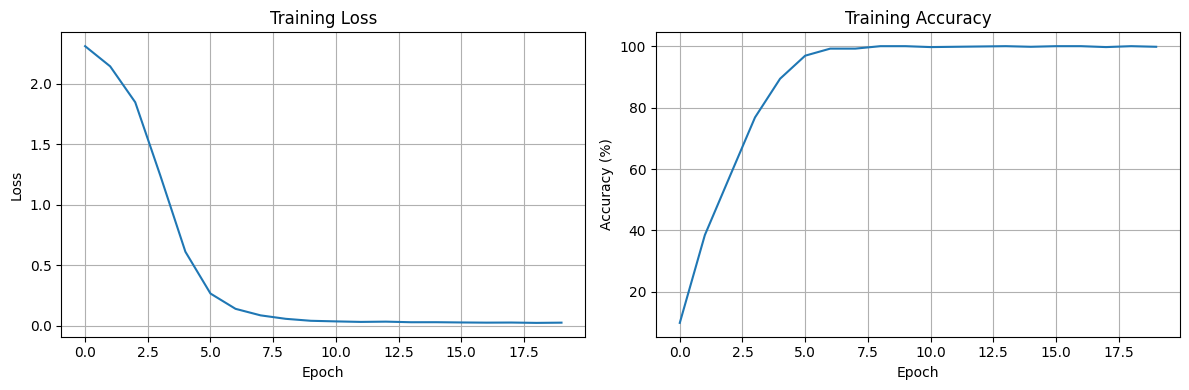

Model saved to model.pth
训练完成！


In [5]:
#完整的训练流程
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

# 假设我们有一些训练数据（这里用随机数据演示）
# 在实际应用中，你会使用真实的数据集如 MNIST, CIFAR-10 等

# 1. 准备数据
def prepare_data():
    # 生成模拟数据：1000个样本，每个样本784维（类似28x28图像展开）
    num_samples = 1000
    input_size = 784
    num_classes = 10
    
    # 随机生成输入数据和标签
    X = torch.randn(num_samples, input_size)
    y = torch.randint(0, num_classes, (num_samples,))
    
    # 创建数据集和数据加载器
    dataset = TensorDataset(X, y)
    train_loader = DataLoader(dataset, batch_size=32, shuffle=True)
    
    return train_loader

# 2. 定义模型（使用之前定义的神经网络）
class SimpleNeuralNetwork(nn.Module):
    def __init__(self):
        super(SimpleNeuralNetwork, self).__init__()
        self.layer1 = nn.Linear(784, 128)
        self.layer2 = nn.Linear(128, 64)
        self.output_layer = nn.Linear(64, 10)
        self.dropout = nn.Dropout(0.2)  # 添加dropout防止过拟合

    def forward(self, x):
        x = torch.relu(self.layer1(x))
        x = self.dropout(x)  # 在激活后添加dropout
        x = torch.relu(self.layer2(x))
        x = self.dropout(x)
        x = self.output_layer(x)
        return x

# 3. 训练函数
def train_model():
    # 准备数据
    train_loader = prepare_data()
    
    # 初始化模型
    model = SimpleNeuralNetwork()
    
    # 定义损失函数和优化器
    criterion = nn.CrossEntropyLoss()  # 交叉熵损失，适用于多分类
    optimizer = optim.Adam(model.parameters(), lr=0.001)  # Adam优化器
    
    # 学习率调度器（可选）
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.1)
    
    # 记录训练过程中的损失和准确率
    train_losses = []
    train_accuracies = []
    
    # 训练循环
    num_epochs = 20
    
    for epoch in range(num_epochs):
        model.train()  # 设置模型为训练模式（启用dropout等）
        running_loss = 0.0
        correct = 0
        total = 0
        
        for batch_idx, (data, targets) in enumerate(train_loader):
            # 1. 梯度清零
            optimizer.zero_grad()
            
            # 2. 前向传播
            outputs = model(data)
            
            # 3. 计算损失
            loss = criterion(outputs, targets)
            
            # 4. 反向传播
            loss.backward()
            
            # 5. 参数更新
            optimizer.step()
            
            # 统计信息
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
        
        # 更新学习率
        scheduler.step()
        
        # 计算每个epoch的平均损失和准确率
        epoch_loss = running_loss / len(train_loader)
        epoch_accuracy = 100 * correct / total
        
        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)
        
        print(f'Epoch [{epoch+1}/{num_epochs}], '
              f'Loss: {epoch_loss:.4f}, '
              f'Accuracy: {epoch_accuracy:.2f}%')
    
    return model, train_losses, train_accuracies

# 4. 可视化训练过程
def plot_training_curves(losses, accuracies):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    
    # 绘制损失曲线
    ax1.plot(losses)
    ax1.set_title('Training Loss')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.grid(True)
    
    # 绘制准确率曲线
    ax2.plot(accuracies)
    ax2.set_title('Training Accuracy')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

# 5. 模型评估
def evaluate_model(model, test_loader):
    model.eval()  # 设置模型为评估模式（禁用dropout等）
    correct = 0
    total = 0
    
    with torch.no_grad():  # 在评估时不需要计算梯度
        for data, targets in test_loader:
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            total += targets.size(0)
            correct += (predicted == targets).sum().item()
    
    accuracy = 100 * correct / total
    print(f'Test Accuracy: {accuracy:.2f}%')
    return accuracy

# 6. 保存和加载模型
def save_model(model, path='model.pth'):
    torch.save(model.state_dict(), path)
    print(f'Model saved to {path}')

def load_model(model, path='model.pth'):
    model.load_state_dict(torch.load(path))
    model.eval()
    print(f'Model loaded from {path}')
    return model

# 主函数
if __name__ == "__main__":
    # 训练模型
    print("开始训练模型...")
    trained_model, losses, accuracies = train_model()
    
    # 可视化训练过程
    plot_training_curves(losses, accuracies)
    
    # 保存模型
    save_model(trained_model)
    
    print("训练完成！")



In [20]:
def train_with_validation():
    # 准备训练集和验证集
    num_samples = 2000
    X_train = torch.randn(num_samples, 784)
    y_train = torch.randint(0, 10, (num_samples,))
    
    X_val = torch.randn(500, 784)
    y_val = torch.randint(0, 10, (500,))
    
    train_dataset = TensorDataset(X_train, y_train)
    val_dataset = TensorDataset(X_val, y_val)
    
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
    
    # 初始化模型、损失函数、优化器
    model = SimpleNeuralNetwork()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    # 训练循环
    best_val_accuracy = 0
    for epoch in range(30):
        # 训练阶段
        model.train()
        train_loss = 0
        for data, targets in train_loader:
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        
        # 验证阶段
        model.eval()
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for data, targets in val_loader:
                outputs = model(data)
                _, predicted = torch.max(outputs, 1)
                val_total += targets.size(0)
                val_correct += (predicted == targets).sum().item()
        
        val_accuracy = 100 * val_correct / val_total
        
        # 保存最佳模型
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            torch.save(model.state_dict(), 'best_model.pth')
        
        print(f'Epoch {epoch+1}: Train Loss: {train_loss/len(train_loader):.4f}, '
              f'Val Accuracy: {val_accuracy:.2f}%')
    
    return model

In [21]:
train_with_validation()

Epoch 1: Train Loss: 2.3109, Val Accuracy: 7.80%
Epoch 2: Train Loss: 2.1357, Val Accuracy: 8.60%
Epoch 3: Train Loss: 1.7043, Val Accuracy: 9.40%
Epoch 4: Train Loss: 1.0444, Val Accuracy: 11.20%
Epoch 5: Train Loss: 0.5315, Val Accuracy: 9.80%
Epoch 6: Train Loss: 0.2919, Val Accuracy: 7.80%
Epoch 7: Train Loss: 0.1764, Val Accuracy: 8.60%
Epoch 8: Train Loss: 0.1343, Val Accuracy: 8.60%
Epoch 9: Train Loss: 0.1022, Val Accuracy: 7.80%
Epoch 10: Train Loss: 0.0918, Val Accuracy: 8.00%
Epoch 11: Train Loss: 0.0788, Val Accuracy: 8.00%
Epoch 12: Train Loss: 0.0634, Val Accuracy: 8.40%
Epoch 13: Train Loss: 0.0546, Val Accuracy: 8.00%
Epoch 14: Train Loss: 0.0457, Val Accuracy: 8.60%
Epoch 15: Train Loss: 0.0480, Val Accuracy: 9.60%
Epoch 16: Train Loss: 0.0446, Val Accuracy: 10.00%
Epoch 17: Train Loss: 0.0532, Val Accuracy: 9.60%
Epoch 18: Train Loss: 0.0463, Val Accuracy: 9.60%
Epoch 19: Train Loss: 0.0413, Val Accuracy: 11.00%
Epoch 20: Train Loss: 0.0460, Val Accuracy: 10.40%
Epoch

SimpleNeuralNetwork(
  (layer1): Linear(in_features=784, out_features=128, bias=True)
  (layer2): Linear(in_features=128, out_features=64, bias=True)
  (output_layer): Linear(in_features=64, out_features=10, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)